# Map quality analysis — Cluj-Napoca

Actual OSM geometry; controlled text extraction; exploratory ML. No API calls in this notebook. © OpenStreetMap contributors, ODbL. Map flags and generated labels require human review.

In [1]:
from pathlib import Path
import json
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'reports').exists(): root = root.parent
out = root / 'reports' / 'mapqa'
read = lambda name: json.loads((out / name).read_text(encoding='utf-8'))
geometry = read('geometry_summary.json')
ml = read('ml_summary.json')
geometry

{'roads': 14591,
 'barrier_nodes': 849,
 'excluded_geometries': 0,
 'metric_crs': 'EPSG:32634',
 'topological_associations': 1076,
 'nearest_candidates': 65,
 'unassociated_barriers': 5,
 'qa_issue_count': 210,
 'spatial_error_taxonomy': ['missing_geometry',
  'invalid_geometry',
  'very_short_geometry',
  'self_intersection',
  'unusual_residential_speed',
  'unrecognized_oneway',
  'nearest_candidate',
  'unassociated'],
 'note': 'QA flags are review suggestions, not verified map errors. Nearest is not a confirmed connection.'}

## Geometry and barriers

Distances and road lengths use local UTM coordinates in metres. A shared OSM node is a topological connection. A nearest candidate within 10 m is not a verified road barrier.

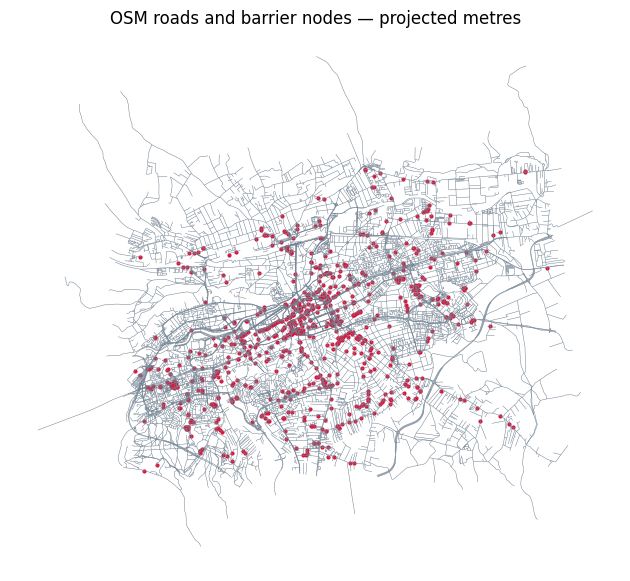

In [2]:
roads = gpd.read_file(out / 'roads.geojson')
barriers = gpd.read_file(out / 'barriers.geojson')
fig, ax = plt.subplots(figsize=(10, 7))
roads.to_crs(geometry['metric_crs']).plot(ax=ax, color='slategray', linewidth=.35)
barriers.to_crs(geometry['metric_crs']).plot(ax=ax, color='crimson', markersize=4)
ax.set_title('OSM roads and barrier nodes — projected metres')
ax.set_axis_off()
plt.show()

In [3]:
associations = pd.DataFrame(read('barrier_associations.json'))
associations.groupby('method').agg(road_node_pairs=('node_id','count'), unique_nodes=('node_id','nunique'))

,road_node_pairs,unique_nodes
method,,
nearest_candidate,65,65
shared_node,1076,779
unassociated,5,5


## Classification and regression

Group-separated test sets by road name/way ID. Classification excludes highway; regression excludes maxspeed. Numeric speed labels are OSM tags, not audited legal limits. Nearby-road and mapping-practice correlations remain possible.

In [4]:
classification = pd.DataFrame({name: result['report']['weighted avg'] for name, result in ml['classification'].items()}).T
classification

,precision,recall,f1-score,support
majority,0.211460,0.459848,0.289701,3549.0
random_forest,0.714258,0.709496,0.702573,3549.0


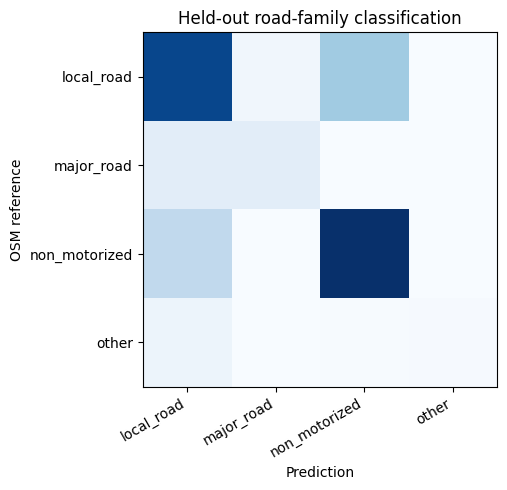

In [5]:
matrix = ml['classification']['random_forest']['confusion_matrix']
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(matrix['values'], cmap='Blues')
ax.set_xticks(range(len(matrix['labels'])), matrix['labels'], rotation=30, ha='right')
ax.set_yticks(range(len(matrix['labels'])), matrix['labels'])
ax.set_xlabel('Prediction'); ax.set_ylabel('OSM reference')
ax.set_title('Held-out road-family classification')
plt.tight_layout(); plt.show()

In [6]:
pd.DataFrame(ml['regression']['models']).T

,mae_kmh,rmse_kmh,r2
median,5.960784,10.810307,-0.060809
random_forest,3.622836,6.526385,0.613360


## Clustering and anomaly suggestions

DBSCAN uses centroids, eps=200 m. IsolationForest flags are suggestions, not independently verified map errors.

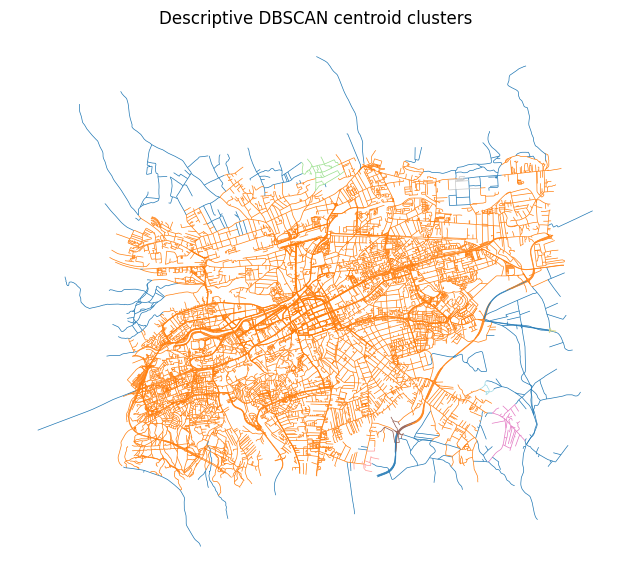

({'method': 'DBSCAN on projected road centroids',
  'eps_m': 200,
  'min_samples': 8,
  'clusters': 8,
  'noise_count': 226,
  'reference_labels': None},
 {'method': 'IsolationForest', 'suggestions': 438, 'verified_errors': None})

In [7]:
layers = gpd.read_file(out / 'ml_roads.geojson')
fig, ax = plt.subplots(figsize=(10, 7))
layers.to_crs(geometry['metric_crs']).plot(column='cluster', ax=ax, cmap='tab20', linewidth=.5)
ax.set_axis_off(); ax.set_title('Descriptive DBSCAN centroid clusters'); plt.show()
ml['clustering'], ml['anomalies']

## Local LangChain prompt evaluation

Compare only identical splits. v4/v5 operate on supplied evidence, unlike the legacy masked-tag experiment. Hybrid results include deterministic Python guards. Null/unknown support can inflate scores; inspect per-class metrics and errors. Generated proposals are excluded pending human review.

In [8]:
runs = [json.loads(p.read_text(encoding='utf-8')) for p in sorted((out / 'benchmarks').glob('*/benchmark_summary.json'))]
pd.DataFrame([{k: r[k] for k in ('mode','prompt','split','n','exact_match_rate','failure_rate')} for r in runs])

,mode,prompt,split,n,exact_match_rate,failure_rate
0,hybrid,v4,dev,80,0.000000,0.000000
1,hybrid,v4,hard,15,0.666667,0.000000
2,hybrid,v5,dev,80,0.025000,0.000000
3,hybrid,v5,hard,15,0.666667,0.000000
4,hybrid,v5,test,40,0.000000,0.000000
5,hybrid,v6,dev,80,0.812500,0.000000
6,hybrid,v6,hard,15,0.866667,0.066667
7,hybrid,v6,test_final,40,0.900000,0.000000
8,langchain,v4,dev,80,0.000000,0.000000
9,langchain,v4,hard,15,0.266667,0.000000


In [9]:
final = next((r for r in runs if r['mode']=='langchain' and r['prompt']=='v6' and r['split']=='test_final'), None)
if final:
    display(pd.DataFrame({f: {'known_reference_n': s['count'] - s['unknown_reference_count'], 'known_accuracy': s['known_reference_accuracy']} for f, s in final['attributes'].items()}).T)
# Zero known numeric speeds means final numeric-speed extraction is not measured.

,known_reference_n,known_accuracy
road_type,40.0,1.000000
speed_limit_kmh,0.0,NaN
surface,18.0,1.000000
oneway,3.0,0.666667
barrier_present,40.0,0.925000
barrier_type,37.0,1.000000
anomaly_flag,40.0,1.000000
input_instruction_detected,40.0,1.000000


In [10]:
examples = []
for p in sorted((out / 'benchmarks').glob('langchain*dev/error_examples.json')):
    examples.extend(json.loads(p.read_text(encoding='utf-8'))[:2])
examples

[{'segment_id': 'evidence-987114526',
  'input': {'osm_tags': {},
   'context_description': 'Categoria drumului: service. Limita numerica inregistrata: 30 km/h. Suprafata: concrete. Sens unic: nu. Bariera pe drum: bariera cu brat.'},
  'expected': {'road_type': 'service',
   'speed_limit_kmh': 30,
   'barrier_present': True,
   'barrier_type': 'lift_gate',
   'surface': 'concrete',
   'oneway': False,
   'confidence_score': 1.0,
   'reasoning_cot': 'Reference normalized from snapshot tags/topologically attached barrier nodes.',
   'anomaly_flag': False,
   'input_instruction_detected': False},
  'actual': {'road_type': 'service',
   'speed_limit_kmh': None,
   'barrier_present': None,
   'barrier_type': 'unknown',
   'surface': 'unknown',
   'oneway': None,
   'confidence_score': 1.0,
   'reasoning_cot': 'The input data specifies the road as a service category, with a numeric maxspeed of 30 km/h, concrete surface, and no one-way restriction. There is a barrier of type lift_gate. No ano

## Reproducibility and limits

Snapshot and split SHA-256 hashes are stored in data/mapqa manifests. v4/v5 omitted optional fields; v6 requires every field. The initial evidence test was consumed; test_final is a new grouped hold-out reserved before freezing v6. Reference integrity is automatic; human field verification remains pending. Cloud Claude/OpenAI benchmarks and professional GIS experience are not claimed. The legacy masked-tag hold-out remains untouched.

In [11]:
read('reference_audit.json')

{'records_checked': 160,
 'source_integrity': 'passed',
 'group_overlap': 0,
 'human_field_verification': False,
 'checked_at': '2026-10-11T18:47:57.452660+00:00'}